# Домашняя работа

## Задание

1) Сгенерировать 20 изображений кошек размером 20x20 пикселей, и 20 изображений собак размером 20x20 пикселей.

2) Обучить четыре решающих схемы чтобы отличать кошек от собак.

Решения должны быть:

- решающее дерево

- метод опорных векторов

- метод главных компонент + решающее дерево

- ансамблевый метод на основе решающих деревьев

3) Для каждого из методов оценить качество.

4) Для одного из методов выбрать изображение, которое он определяет правильно и изменить один пиксель на изображении так, чтобы алгоритм ошибся.

Датасет сгенерированных изображений присоединить к ответу.

Программу демонстрирующую решение (.ipynb) присоединить к ответу (или дать ссылку на колаб).

## Датасет

### Пробую использовать датасет с Kaggle

In [334]:
import kagglehub
from pathlib import Path
import os

# Скачиваем датасет с kaggle
path = Path(kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset"))

# Смотрим, что там находится
print(os.listdir(path))

Using Colab cache for faster access to the 'dog-and-cat-classification-dataset' dataset.
['PetImages']


In [335]:
# Открываем дальше
path = path / "PetImages"
print(os.listdir(path))


['Dog', 'Cat']


In [336]:
print(cats := os.listdir(path / "Cat"))
print(dogs := os.listdir(path / "Dog"))

['7981.jpg', '6234.jpg', '1269.jpg', '3863.jpg', '6241.jpg', '10304.jpg', '623.jpg', '2193.jpg', '11925.jpg', '3750.jpg', '11378.jpg', '2008.jpg', '10730.jpg', '5982.jpg', '7737.jpg', '2081.jpg', '10597.jpg', '6588.jpg', '10054.jpg', '7966.jpg', '3919.jpg', '6197.jpg', '10924.jpg', '6399.jpg', '9960.jpg', '3757.jpg', '9131.jpg', '9620.jpg', '9062.jpg', '4489.jpg', '3138.jpg', '10213.jpg', '3417.jpg', '6074.jpg', '5705.jpg', '8953.jpg', '764.jpg', '5307.jpg', '7894.jpg', '5039.jpg', '10305.jpg', '4407.jpg', '1700.jpg', '1786.jpg', '2907.jpg', '8930.jpg', '11138.jpg', '6324.jpg', '1075.jpg', '4969.jpg', '8983.jpg', '5584.jpg', '10627.jpg', '9697.jpg', '3501.jpg', '10037.jpg', '2863.jpg', '771.jpg', '8352.jpg', '208.jpg', '12167.jpg', '11868.jpg', '4640.jpg', '7222.jpg', '5333.jpg', '4125.jpg', '6560.jpg', '2628.jpg', '10162.jpg', '8104.jpg', '3363.jpg', '4009.jpg', '9645.jpg', '9579.jpg', '820.jpg', '6943.jpg', '3228.jpg', '12132.jpg', '8075.jpg', '6272.jpg', '1789.jpg', '6365.jpg', '645

In [337]:
# Берем по 20 картинок
cats = [path / "Cat" / cat for cat in os.listdir(path / "Cat")][:20]
dogs = [path / "Dog" / dog for dog in os.listdir(path / "Dog")][:20]

Размеры (500, 418) (388, 500)


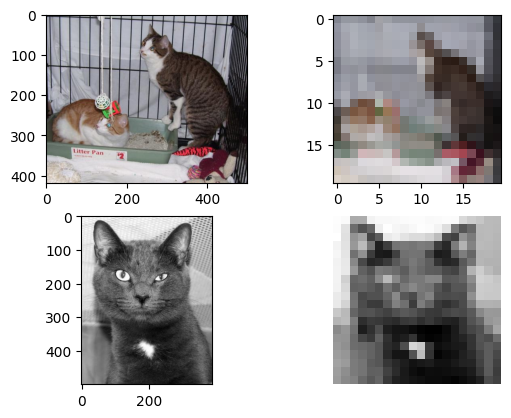

In [338]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

img1 = Image.open(cats[0])
img2 = Image.open(cats[1]).convert("L") # Красим в серое
print("Размеры", img1.size, img2.size)

plt.subplot(2, 2, 1)
plt.imshow(np.array(img1))
plt.subplot(2, 2, 2)
plt.imshow(np.array(img1.resize((20, 20))))
plt.subplot(2, 2, 3)
plt.imshow(np.array(img2), cmap="gray")
plt.subplot(2, 2, 4)
plt.imshow(np.array(img2.resize((20, 20))), cmap="gray")
plt.axis("off")
plt.show()

Выглядит не очень, попробую вывести собак.

Размеры (500, 375) (440, 440)


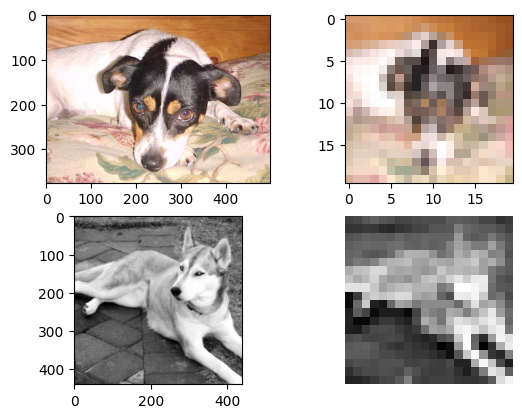

In [339]:
img1 = Image.open(dogs[0])
img2 = Image.open(dogs[1]).convert("L") # Красим в серое
print("Размеры", img1.size, img2.size)

plt.subplot(2, 2, 1)
plt.imshow(np.array(img1))
plt.subplot(2, 2, 2)
plt.imshow(np.array(img1.resize((20, 20))))
plt.subplot(2, 2, 3)
plt.imshow(np.array(img2), cmap="gray")
plt.subplot(2, 2, 4)
plt.imshow(np.array(img2.resize((20, 20))), cmap="gray")
plt.axis("off")
plt.show()

Такой датасет выглядит плачевно.

### Генерация котов и собак

Функция для генерации базового фона с небольшим шумом.

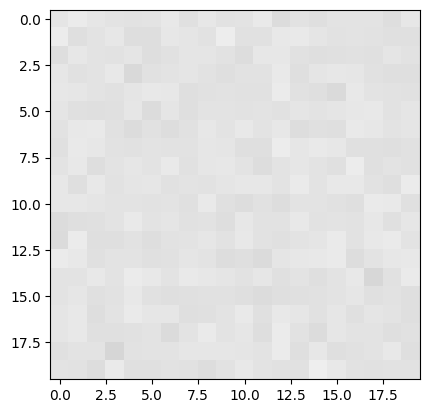

In [340]:
import numpy as np
import matplotlib.pyplot as plt

def get_bg_image() -> np.typing.NDArray:
  """Генерация фона"""
  img = np.random.randint(200, 255, (15, 20, 20)) # 15 картинок размером 20 на 20
  img = img.mean(axis=0)
  return img

plt.imshow(get_bg_image(), cmap="gray", vmin=0, vmax=255)
plt.show()


Функции для рисования готовых фигур на существующих изображениях.

In [341]:
import numpy as np

def draw_ellipse(img: np.typing.NDArray, x: int, y: int, a: int, b: int, color: int = 0) -> None:
    """Нарисовать эллипс на существующем изображении побочным эффектом функции"""
    # x, y - координаты центра
    # a, b - полуось по горизонтали и по вертикали

    if a <= 0 or b <= 0:
        return

    for i in range(max(0, y - b), min(img.shape[0], y + b + 1)):
        for j in range(max(0, x - a), min(img.shape[1], x + a + 1)):
            if (j - x) ** 2 / a ** 2 + (i - y) ** 2 / b ** 2 <= 1:
                img[i, j] = color

def draw_circle(img: np.typing.NDArray, x: int, y: int, r: int, color: int = 0) -> None:
    """Нарисовать круг на существующем изображении побочным эффектом функции"""
    draw_ellipse(img, x, y, r, r, color)
    return img

from typing import Literal

def draw_triangle_down_based(
    img: np.typing.NDArray,
    x: int, y: int,
    height: int,
    color: int = 0,
    x_grow_speed_divisor: int = 2, grow_side: Literal["left"] | Literal["right"] | Literal["both"] = "both"
    ) -> None:
    """Нарисовать смотрящий вверх треугольник побочным эффектом функции"""
    # x, y - координаты конца треугольника сверху (x - это центр у всего треугольника)
    # height - высота треугольника (на сколько строк он уходит вниз)
    # x_grow_speed_divisor - делитель скорости расширения треугольника
    # grow_side - в какую сторону будет расти треугольник

    is_left_grow = grow_side in ["left", "both"]
    is_right_grow = grow_side in ["right", "both"]

    for i in range(height):
        row = y + i
        # расширяем треугольник на каждый слой вниз
        start_x = x - (i // x_grow_speed_divisor * is_left_grow)
        end_x = x + (i // x_grow_speed_divisor * is_right_grow) + 1

        for col in range(start_x, end_x):
            if 0 <= row < img.shape[0] and 0 <= col < img.shape[1]:
                img[row, col] = color

Создаем функцию для генерации котов.

In [342]:
def generate_cat_image(bg_image: np.typing.NDArray | None = None) -> np.typing.NDArray:
    """Генерация кота"""
    if bg_image is None:
        img = get_bg_image()
    else:
        img = bg_image.copy()

    # положение и размер головы
    head_x = np.random.randint(7, 13)
    head_y = np.random.randint(7, 13)
    head_size = np.random.randint(4, 7)

    base_color = np.random.randint(110, 170)
    ear_color = base_color - np.random.randint(20, 50)

    # уши
    ear_speed = np.random.choice([2, 3])
    ear_dx = head_size // 2 + 1
    left_ear_x = head_x - ear_dx
    right_ear_x = head_x + ear_dx
    ear_height = head_size
    ear_y = max(0, head_y - head_size - ear_height + 2)
    draw_triangle_down_based(
        img, left_ear_x, ear_y, ear_height,
        color=ear_color, x_grow_speed_divisor=ear_speed
    )
    draw_triangle_down_based(
        img, right_ear_x, ear_y, ear_height,
        color=ear_color, x_grow_speed_divisor=ear_speed
    )

    # голова
    draw_circle(img, head_x, head_y, head_size, color=base_color)

    # нос чуть ниже центра
    nose_x = head_x
    nose_y = head_y + max(1, head_size // 4)

    # пиксели глаз
    eye_color = np.random.randint(45, 60)
    eye_y = head_y - max(1, head_size // 3)
    eye_dx = max(1, head_size // 2)
    img[eye_y, head_x - eye_dx] = eye_color
    img[eye_y, head_x + eye_dx] = eye_color

    # пиксель носа
    nose_color = np.random.randint(30, 50)
    img[nose_y, nose_x] = nose_color

    # ротик под носом
    mouth_color = nose_color + np.random.randint(1, 10)
    mouth_y = nose_y + 1
    img[mouth_y, nose_x - 1] = mouth_color
    img[mouth_y, nose_x + 1] = mouth_color

    return img

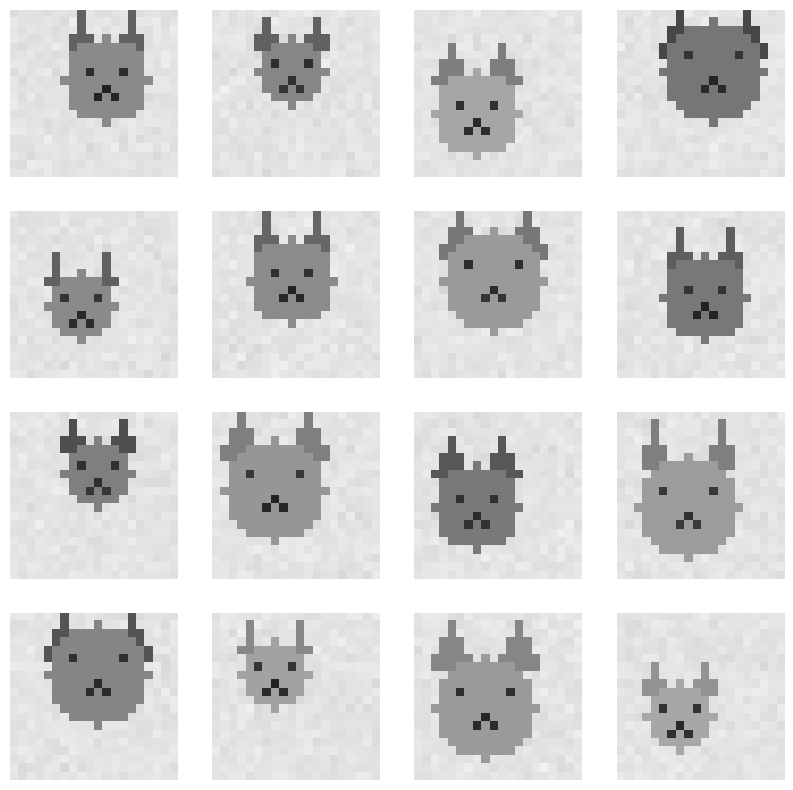

In [343]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for i in range(4):
    for j in range(4):
        axes[i, j].imshow(generate_cat_image(), cmap="gray", vmin=0, vmax=255)
        axes[i, j].axis("off")
plt.show()

Функция для генерации собак.

In [344]:
def generate_dog_image(bg_image: np.typing.NDArray | None = None) -> np.typing.NDArray:
    """Генерация собаки с вислоухими или круглыми ушами"""
    if bg_image is None:
        img = get_bg_image()
    else:
        img = bg_image.copy()

    h, w = img.shape

    # положение и размер головы
    head_x = np.random.randint(7, 13)
    head_y = np.random.randint(7, 13)
    head_size = np.random.randint(5, 7)

    base_color = np.random.randint(110, 170)
    ear_color = base_color - np.random.randint(20, 50)

    # уши
    ear_type = np.random.choice(["triangle", "round"])

    if ear_type == "triangle":
        # вислоухие уши (треугольники)
        ear_speed = np.random.choice([1, 2])
        ear_height = head_size + 2
        ear_y = max(0, head_y - head_size - 1)
        ear_dx = max(1, head_size // 2)

        left_ear_x = head_x - ear_dx
        right_ear_x = head_x + ear_dx

        draw_triangle_down_based(
            img, left_ear_x, ear_y, ear_height,
            color=ear_color, x_grow_speed_divisor=ear_speed, grow_side="left"
        )
        draw_triangle_down_based(
            img, right_ear_x, ear_y, ear_height,
            color=ear_color, x_grow_speed_divisor=ear_speed, grow_side="right"
        )
    else:
        # овальные уши
        ear_a = max(1, head_size // 2)
        ear_b = max(1, head_size - 1)
        ear_y = head_y

        left_ear_x = head_x - head_size
        right_ear_x = head_x + head_size

        draw_ellipse(img, left_ear_x, ear_y, ear_a, ear_b, color=ear_color)
        draw_ellipse(img, right_ear_x, ear_y, ear_a, ear_b, color=ear_color)

    # голова
    draw_circle(img, head_x, head_y, head_size, color=base_color)

    # пиксели глаз
    eye_color = np.random.randint(30, 50)
    eye_y = head_y - max(1, head_size // 3)
    eye_dx = max(1, head_size // 2)

    img[eye_y, head_x - eye_dx] = eye_color
    img[eye_y, head_x + eye_dx] = eye_color

    # нос
    nose_color = np.random.randint(20, 40)
    nose_y = head_y + max(1, head_size // 3)

    img[nose_y, head_x] = nose_color
    img[nose_y, head_x - 1] = nose_color
    img[nose_y, head_x + 1] = nose_color

    # ротик
    mouth_color = nose_color + np.random.randint(10, 30)
    mouth_y = nose_y + 1

    img[mouth_y, head_x] = mouth_color
    img[mouth_y + 1, head_x] = 180 # язык

    return img

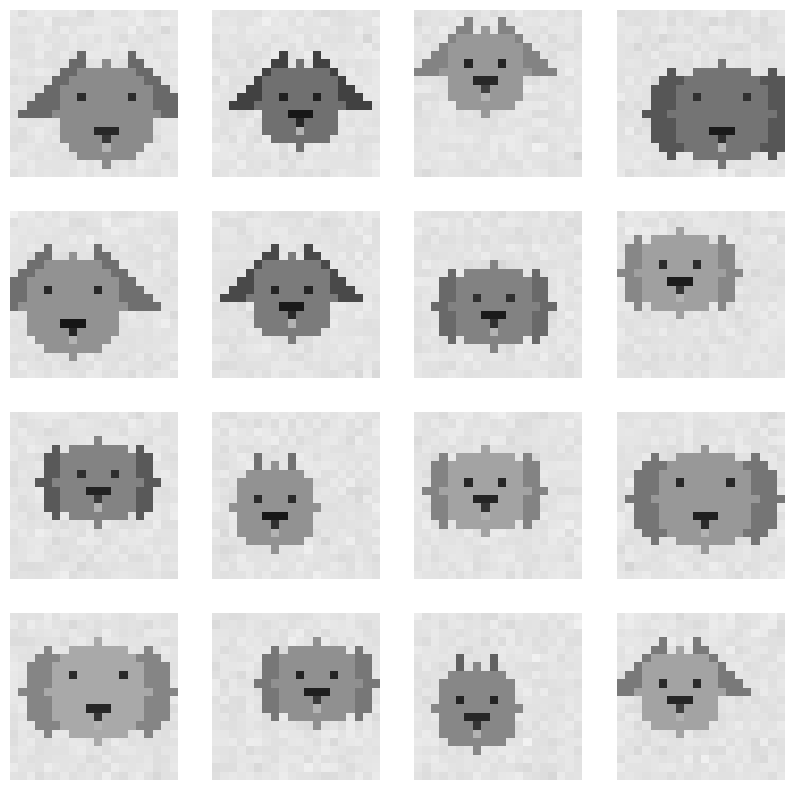

In [345]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for i in range(4):
    for j in range(4):
        axes[i, j].imshow(generate_dog_image(), cmap="gray", vmin=0, vmax=255)
        axes[i, j].axis("off")
plt.show()

Функции для генерации изображений собак и котов сделали, теперь создаем датасет

### Создание самого датасета

In [346]:
import numpy as np

# генерируем по 20 изображений котов и собак
cats = [generate_cat_image() for _ in range(20)]
dogs = [generate_dog_image() for _ in range(20)]

# делаем из изображений векторы
X_cats = np.array([img.flatten() for img in cats])
X_dogs = np.array([img.flatten() for img in dogs])

# объединяем в один датасет
X = np.concatenate([X_cats, X_dogs])

# вектор ответов y: 0 - кот, 1 - собака
y = np.array([0] * 20 + [1] * 20)

print(f"40 картинок: {X.shape}")
print(f"Метки: {y.shape}")

40 картинок: (40, 400)
Метки: (40,)


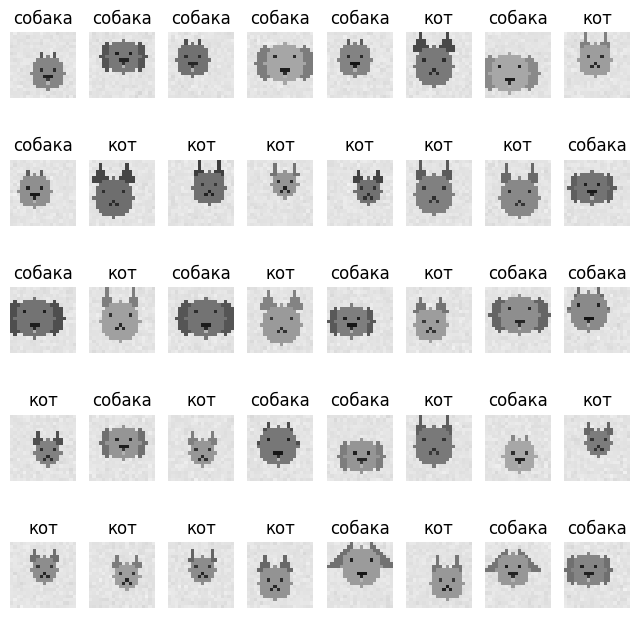

In [347]:
from sklearn.utils import shuffle

# мешаем наш датасет и метки
X, y = shuffle(X, y) # ! Не изменяем эти массивы, чтобы использовать эти данные для всех

# выводим
fig, axes = plt.subplots(5, 8, figsize=(8, 8))
for i in range(40):
    axis = axes[i // 8, i % 8]
    axis.axis("off")
    axis.set_title("кот" if y[i] == 0 else "собака")
    axis.imshow(X[i].reshape(20, 20), cmap="gray", vmin=0, vmax=255)

plt.show()

Наш датасет готов!

In [402]:
import os
from PIL import Image

os.makedirs("dataset/cats", exist_ok=True)
os.makedirs("dataset/dogs", exist_ok=True)

cat_count = 0
dog_count = 0

for i in range(len(X)):
    img_array = X[i].reshape(20, 20).astype(np.uint8)
    img = Image.fromarray(img_array, mode='L')

    if y[i] == 0:
        img.save(f"data/cats/{cat_count}.png")
        cat_count += 1
    else:
        img.save(f"data/dogs/{dog_count}.png")
        dog_count += 1

print("Картинки успешно сохранены")

Картинки успешно сохранены


/tmp/ipykernel_6940/2636854895.py:12: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(img_array, mode='L')


### Функция для генерации массива и меток со случайными существами

In [349]:
def generate_random_creatures(lenght: int = 10) -> tuple[np.typing.NDArray, np.typing.NDArray]:
  """Генерирует массив указанной длины из случайных существ: котов или собак"""
  y = np.random.randint(0, 2, size=lenght) # метки
  X = [generate_cat_image() if label == 0 else generate_dog_image() for label in y]

  X = [img.flatten() for img in X]
  return np.array(X), np.array(y)


Функция для генерации суещств случайных. Нужна для оценки наших моделей и генерации датасета побольше.
Важно то, что функция генерирует примерно одинаковое количество котов и собак. То есть, мы работаем со сбалансированными датасетами. Поэтому метрика accuracy нас устраивает.

### Датасет для обучения большего размера

Создаю датасет размером больше, чтобы сравнивать модели, которые мы получаем в зависимости от размера датасета.
Существует проклятие размерности, которое объясняет плохие результаты в обучении на небольшом датасете данных, которые имеют много параметров. Есть правило, которое помогает решать эту проблему, - "10 к 1", оно говорит, что для каждого признака N нам нужно иметь 10*N - 100*N записей в датасете. То есть, в нашем датасете мы имеем 400 признаков (20 * 20), следовательно, нам стоит иметь от 4000 до 40000 картинок для обучения моделей.

In [350]:
X_big, y_big = generate_random_creatures(4000) # генерация случайных
# Не изменяем эти данные, чтобы сравнить между моделями

### Датасет для оценки наших моделей

Этот датасет я буду использовать для оценки моделей.

In [351]:
X_test, y_test = generate_random_creatures(4000) # генерация случайных
# Не изменяем эти данные, чтобы сравнить между моделями

## Решение

### Решающее дерево

#### Обучаем модель на нашем датасете

Пробуем создать решающее дерево на основе 40 изображений нашего датасета.

Оценка на начальных данных: 1.0


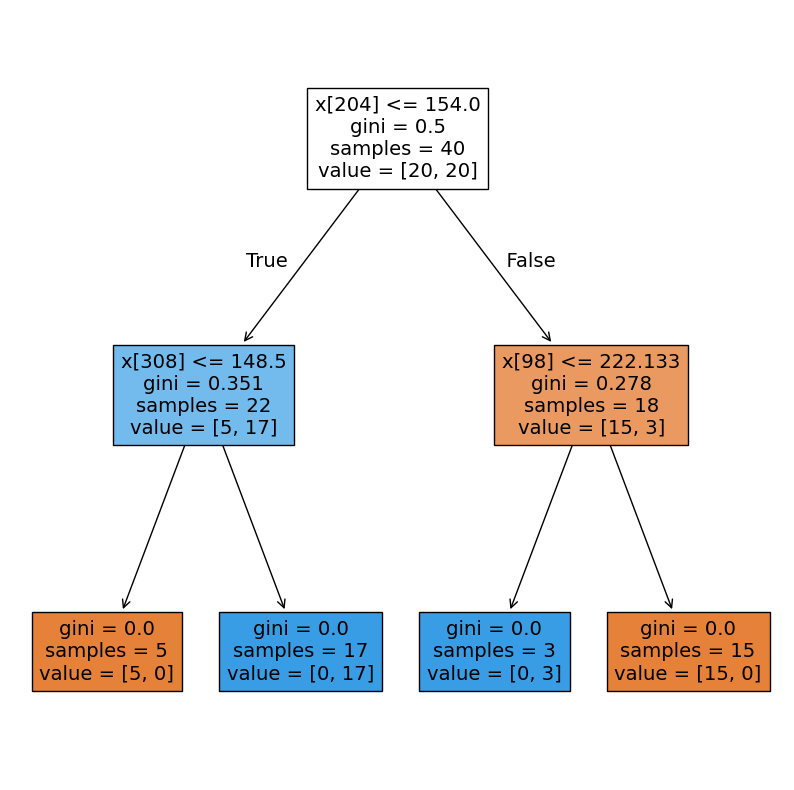

              precision    recall  f1-score   support

     кот (0)       0.57      0.74      0.64      1977
  собака (1)       0.64      0.45      0.53      2023

    accuracy                           0.59      4000
   macro avg       0.60      0.59      0.58      4000
weighted avg       0.60      0.59      0.58      4000



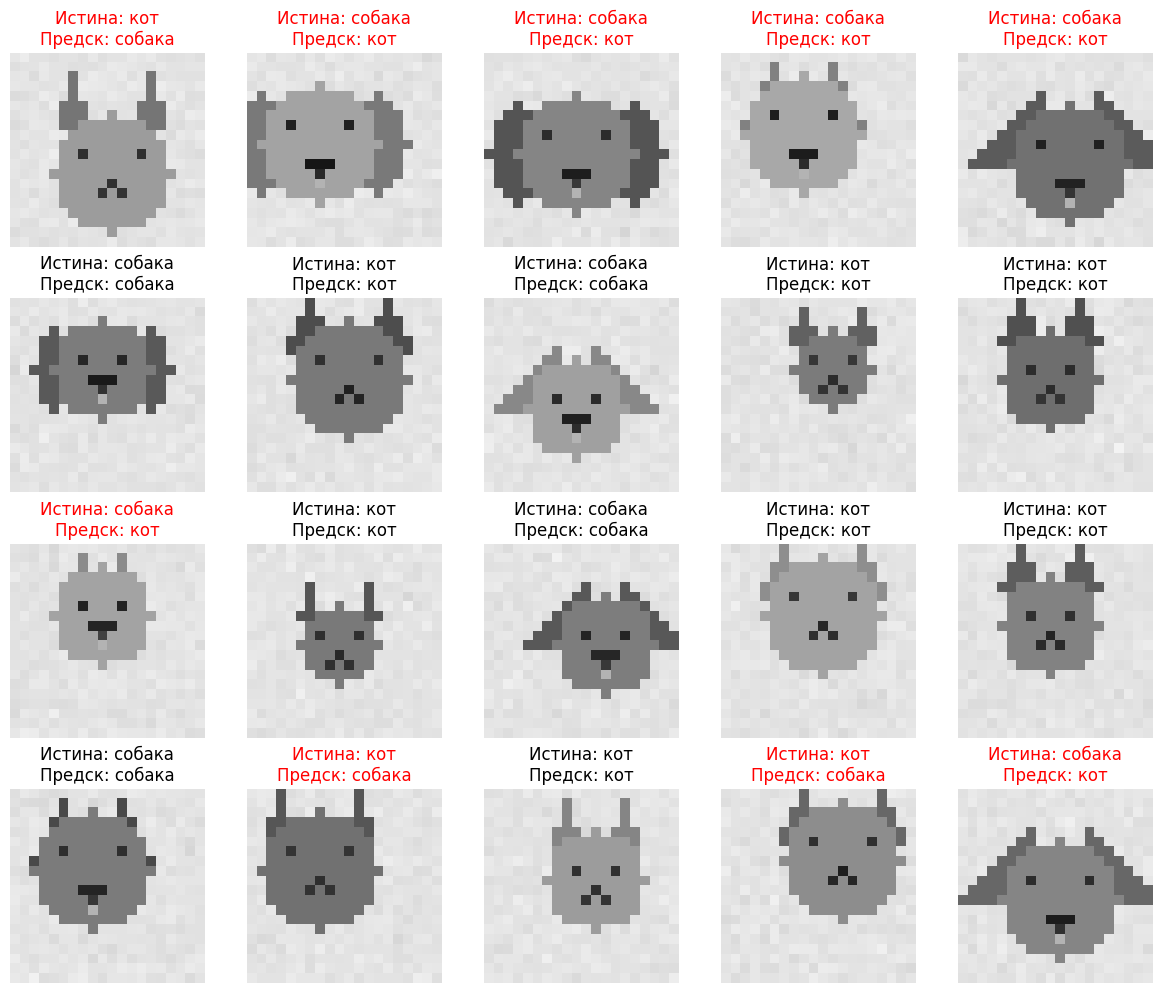

In [352]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

clf = DecisionTreeClassifier()
clf.fit(X, y)
print("Оценка на начальных данных:", clf.score(X, y))

plt.figure(figsize=(10, 10))
plot_tree(clf, filled=True)
plt.show()

from sklearn.metrics import classification_report

y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["кот (0)", "собака (1)"]))

fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for i in range(20):
    axis = axes[i // 5, i % 5]
    axis.axis("off")

    true_label = "кот" if y_test[i] == 0 else "собака"
    pred_label = "кот" if y_pred[i] == 0 else "собака"

    #если ошибка, то красим заголовок в красный
    color = "black" if true_label == pred_label else "red"
    axis.set_title(f"Истина: {true_label}\nПредск: {pred_label}", color=color)

    axis.imshow(X_test[i].reshape(20, 20), cmap="gray", vmin=0, vmax=255)

plt.tight_layout()
plt.show()


Оценка от начальных данных = 1.0. Дерево выглядит простым и небольшим. Проверим на случайных данных.

Мы получили модель, которая угадывает класс существа немного лучше, чем случайно: ~0.56.
Это связано с тем, что наш датасет состоит всего из 40 картинок, а возможных параметров у нас 400. Дерево решений просто нашел некоторые удачные пиксели из наших 40 изображений, от которых зависит то, какое существо из этих 40 мы имеем. Слишком мало данных для обучения для такого количества параметров.

#### Обучение на большем количестве данных

Оценка на начальных данных: 1.0


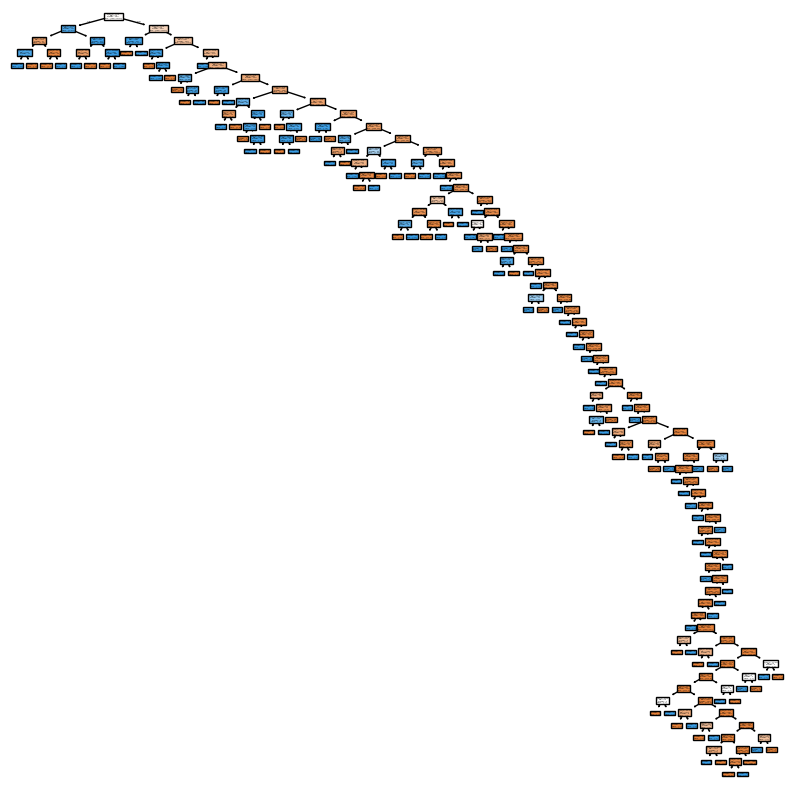

              precision    recall  f1-score   support

     кот (0)       0.95      0.96      0.96      1977
  собака (1)       0.96      0.96      0.96      2023

    accuracy                           0.96      4000
   macro avg       0.96      0.96      0.96      4000
weighted avg       0.96      0.96      0.96      4000



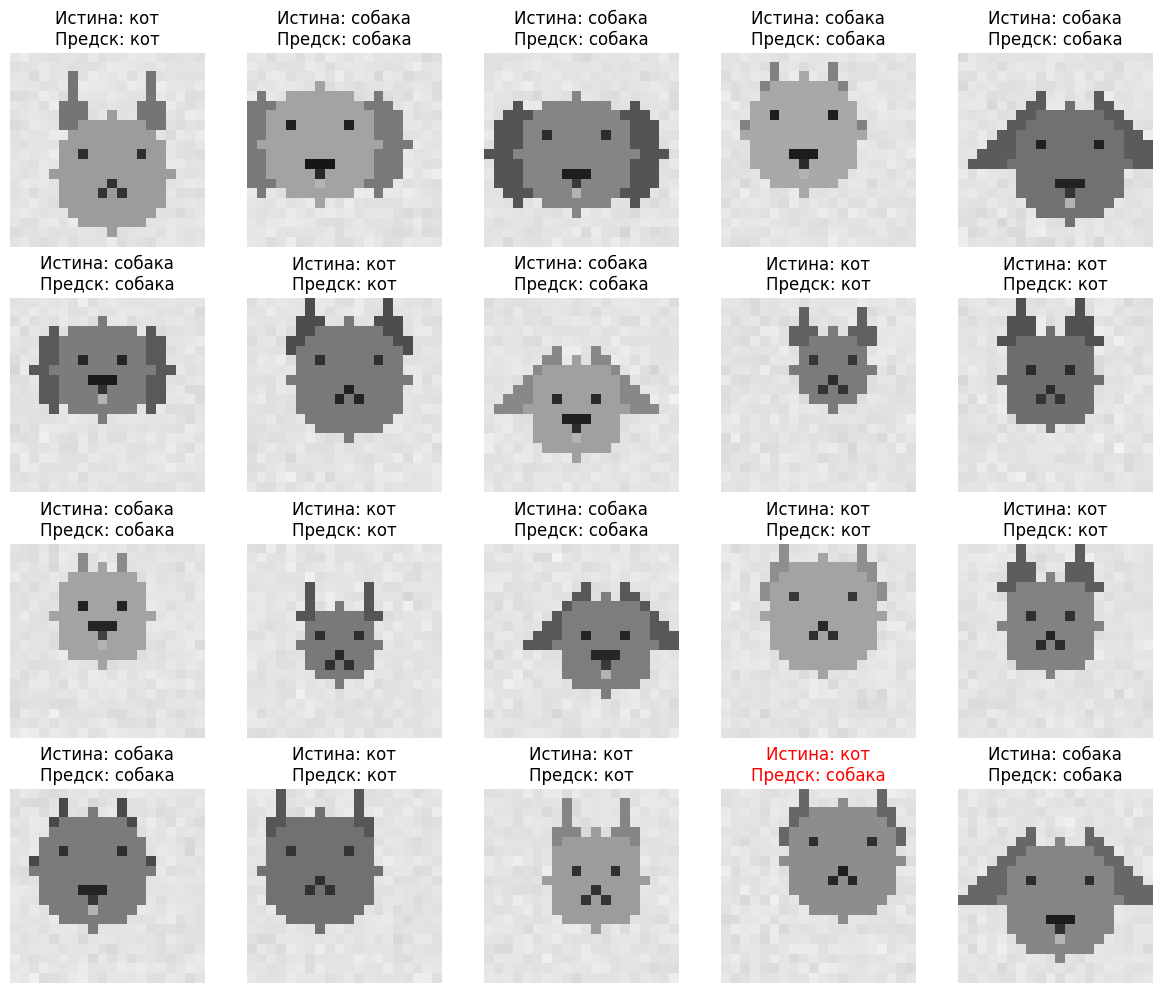

In [354]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report

clf = DecisionTreeClassifier()
clf.fit(X_big, y_big)
print("Оценка на начальных данных:", clf.score(X_big, y_big))

plt.figure(figsize=(10, 10))
plot_tree(clf, filled=True)
plt.show()

y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["кот (0)", "собака (1)"]))

fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for i in range(20):
    axis = axes[i // 5, i % 5]
    axis.axis("off")

    true_label = "кот" if y_test[i] == 0 else "собака"
    pred_label = "кот" if y_pred[i] == 0 else "собака"

    #если ошибка, то красим заголовок в красный
    color = "black" if true_label == pred_label else "red"
    axis.set_title(f"Истина: {true_label}\nПредск: {pred_label}", color=color)

    axis.imshow(X_test[i].reshape(20, 20), cmap="gray", vmin=0, vmax=255)

plt.tight_layout()
plt.show()

Здесь мы получаем оценку на начальных данных = 1, как и должно быть.
Ну вот, теперь на тестовых данных наша модель уже может неплохо различать собак и кошек (0.96), но мы имеем очень большое дерево решений для этого и мы можем получить результат лучше.

### Метод опорных векторов

#### Обучаем модель на нашем датасете

Оценка на начальных данных: 0.95
              precision    recall  f1-score   support

     кот (0)       0.76      0.82      0.79      1977
  собака (1)       0.81      0.75      0.78      2023

    accuracy                           0.78      4000
   macro avg       0.78      0.78      0.78      4000
weighted avg       0.78      0.78      0.78      4000



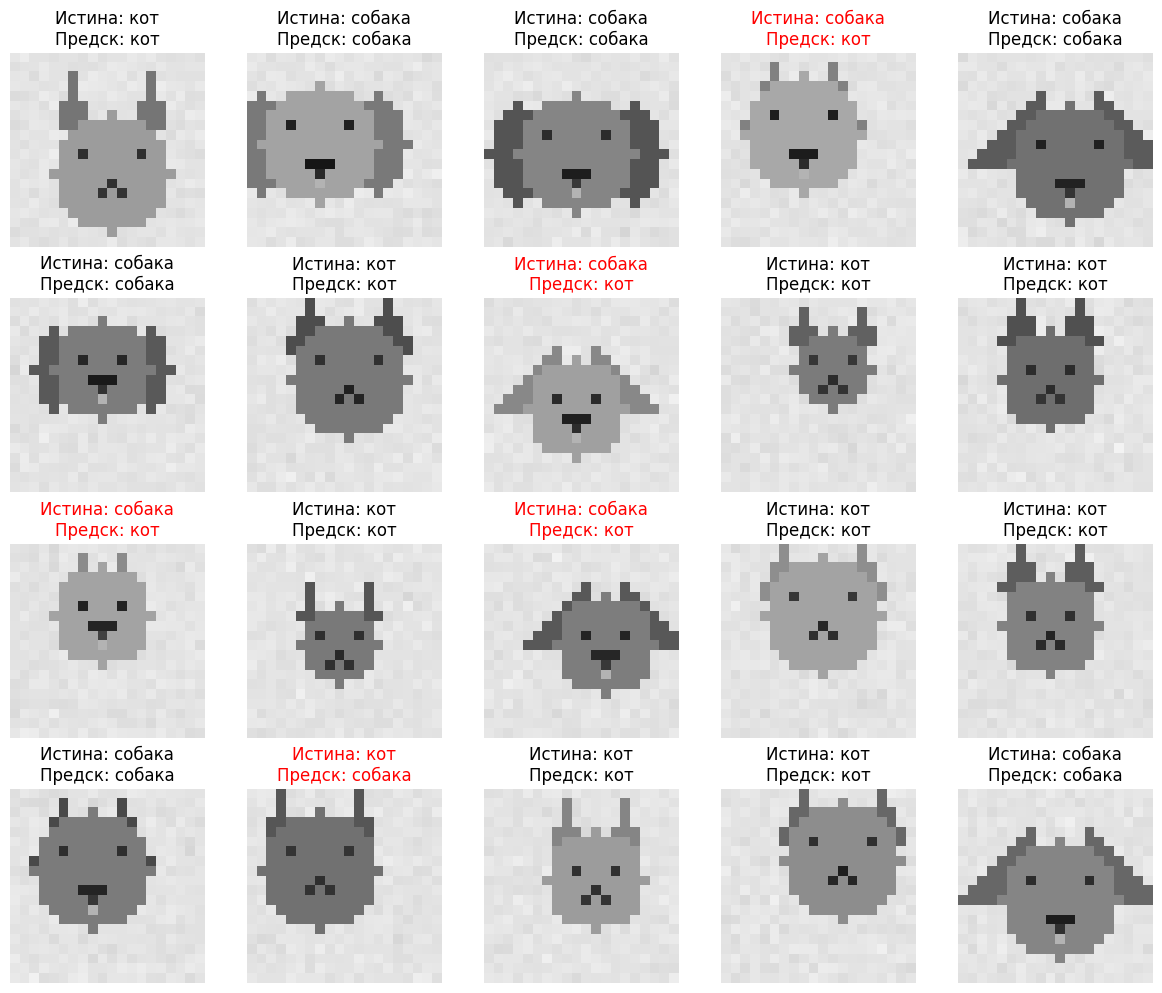

In [355]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report

clf = SVC()
clf.fit(X, y)
print("Оценка на начальных данных:", clf.score(X, y))

y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["кот (0)", "собака (1)"]))

fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for i in range(20):
    axis = axes[i // 5, i % 5]
    axis.axis("off")

    true_label = "кот" if y_test[i] == 0 else "собака"
    pred_label = "кот" if y_pred[i] == 0 else "собака"

    #если ошибка, то красим заголовок в красный
    color = "black" if true_label == pred_label else "red"
    axis.set_title(f"Истина: {true_label}\nПредск: {pred_label}", color=color)

    axis.imshow(X_test[i].reshape(20, 20), cmap="gray", vmin=0, vmax=255)

plt.tight_layout()
plt.show()


Оценка от начальных данных = 0.95. Мы получили модель, которая угадывает класс существа с вероятностью ~0.78. Это уже намного лучше, чем с деревом решений на 40 изображениях.
Это связано с тем, что наш датасет состоит всего из 20 картинок, а возможных параметров у нас 400. Дерево решений просто нашел некоторые удачные пиксели из наших 20 изображений, от которых зависит то, какое существо из этих 20 мы имеем. Слишком мало данных для обучения для такого количества параметров.

#### Обучение на большем количестве данных

Оценка на начальных данных: 0.99975
              precision    recall  f1-score   support

     кот (0)       1.00      1.00      1.00      1977
  собака (1)       1.00      1.00      1.00      2023

    accuracy                           1.00      4000
   macro avg       1.00      1.00      1.00      4000
weighted avg       1.00      1.00      1.00      4000

Accuracy_score:  0.999


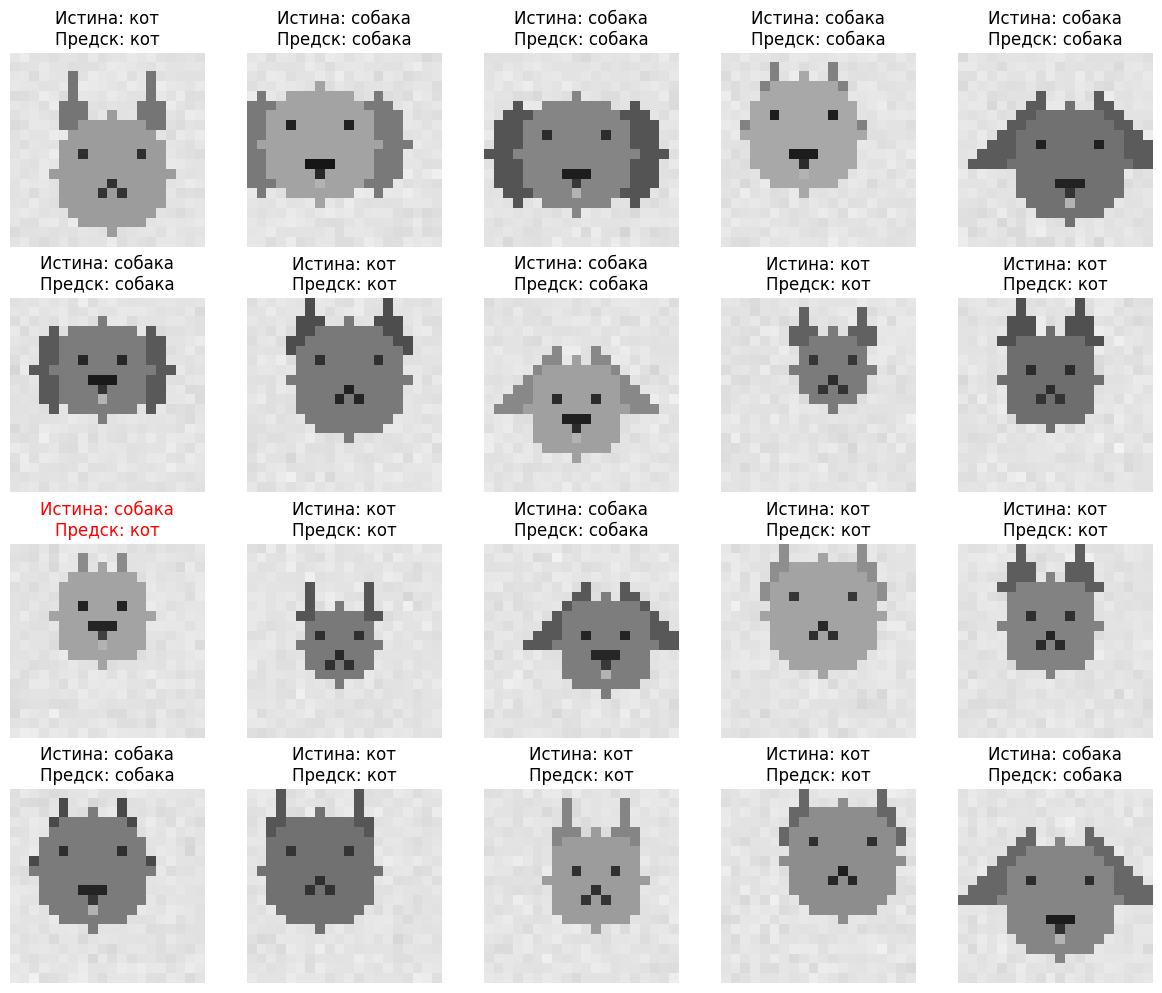

In [358]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score

clf = SVC()
clf.fit(X_big, y_big)
print("Оценка на начальных данных:", clf.score(X_big, y_big))

y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["кот (0)", "собака (1)"]))
print("Accuracy_score: ", accuracy_score(y_test, y_pred))

fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for i in range(20):
    axis = axes[i // 5, i % 5]
    axis.axis("off")

    true_label = "кот" if y_test[i] == 0 else "собака"
    pred_label = "кот" if y_pred[i] == 0 else "собака"

    #если ошибка, то красим заголовок в красный
    color = "black" if true_label == pred_label else "red"
    axis.set_title(f"Истина: {true_label}\nПредск: {pred_label}", color=color)

    axis.imshow(X_test[i].reshape(20, 20), cmap="gray", vmin=0, vmax=255)

plt.tight_layout()
plt.show()

Здесь мы уже получаем очень хорошую оценку ~0.999. Это результат куда лучше, чем в тупую построенное дерево решений. Нам повезло увидеть неправильное предсказание нашей модели.

### Метод главных компонент + решающее дерево

Здесь мы постараемся уменьшить размерность наших данных, а потом отправить их в дерево решений. Это должно улучшить модель, потому что дерево решений с большим количеством параметров просто пытается запомнить удачные пиксели. Здесь же мы сможем привести к более общим параметрам наши данные, что не позволит дереву зашить определенные пиксели.

#### Обучаем модель на нашем датасете

PCA оставил 40 компонент из 400
Оценка на начальных данных: 1.0


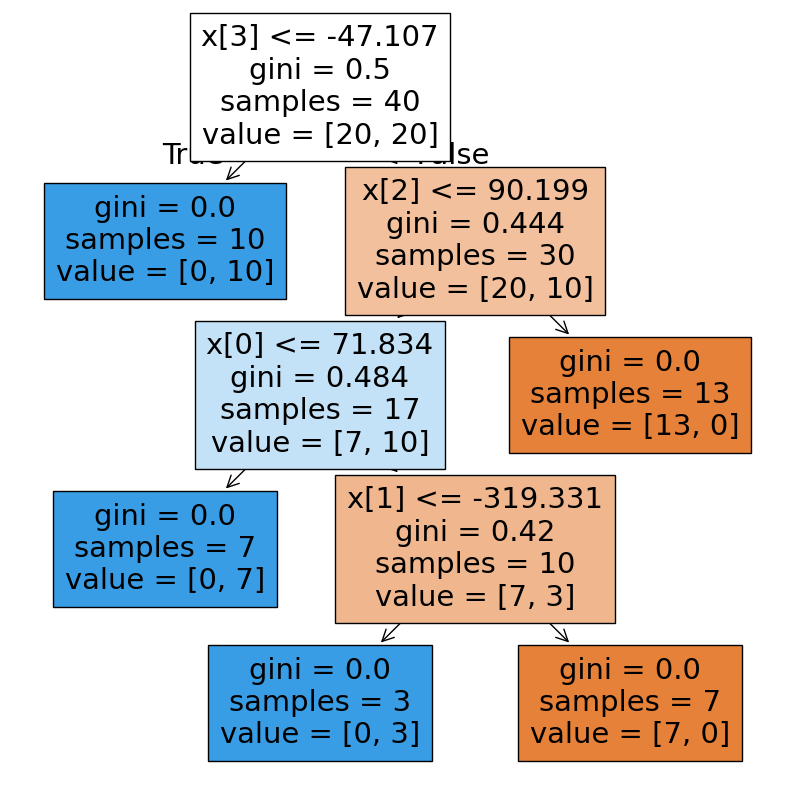

              precision    recall  f1-score   support

     кот (0)       0.76      0.88      0.81      1977
  собака (1)       0.86      0.73      0.79      2023

    accuracy                           0.80      4000
   macro avg       0.81      0.80      0.80      4000
weighted avg       0.81      0.80      0.80      4000



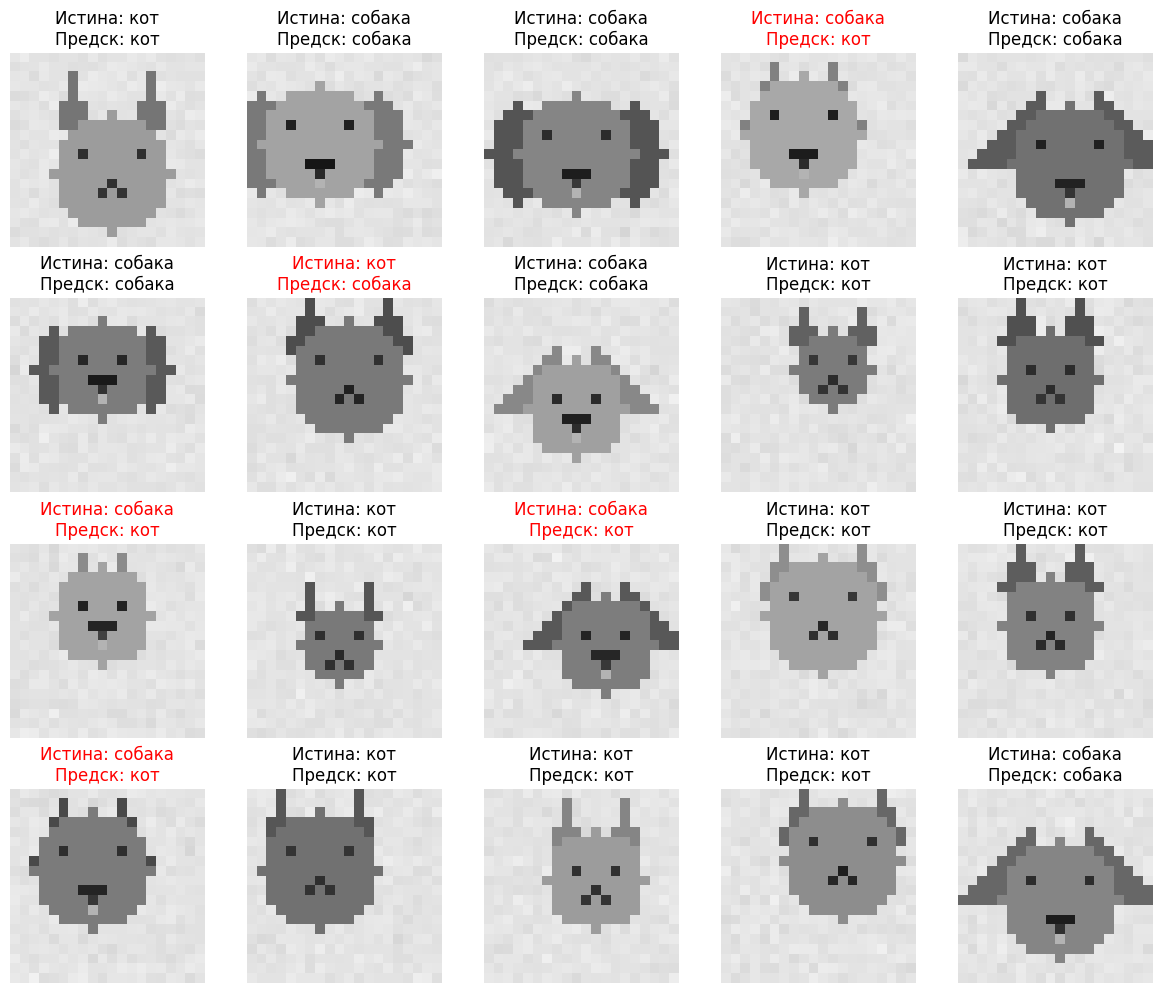

In [364]:
from sklearn.metrics import classification_report
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier, plot_tree

pca = PCA().fit(X)
X_pca = pca.transform(X)

print("PCA оставил", len(pca.components_), "компонент из 400")

clf = DecisionTreeClassifier()
clf.fit(X_pca, y)
print("Оценка на начальных данных:", clf.score(X_pca, y))

plt.figure(figsize=(10, 10))
plot_tree(clf, filled=True)
plt.show()

from sklearn.metrics import classification_report

y_pred = clf.predict(pca.transform(X_test))
print(classification_report(y_test, y_pred, target_names=["кот (0)", "собака (1)"]))

fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for i in range(20):
    axis = axes[i // 5, i % 5]
    axis.axis("off")

    true_label = "кот" if y_test[i] == 0 else "собака"
    pred_label = "кот" if y_pred[i] == 0 else "собака"

    #если ошибка, то красим заголовок в красный
    color = "black" if true_label == pred_label else "red"
    axis.set_title(f"Истина: {true_label}\nПредск: {pred_label}", color=color)

    axis.imshow(X_test[i].reshape(20, 20), cmap="gray", vmin=0, vmax=255)

plt.tight_layout()
plt.show()


Оценка от начальных данных = 1, что присуще дереву решений. Дерево решений небольшое. Теперь мы получили точность ~0.80. Неплохой результат. Это связано с тем, что дерево решений теперь запоминает не определенные пиксели, а 40 признаков, которые PCA собрал из 400.

### Ансамблевый метод на основе решающих деревьев

Мы будем объединять несколько моделей решающих деревьев, чтобы попытаться получить лучший результат. У нас есть ансамблевых методов: bagging, stacking, boosting.

Для получения моделей в bagging и stacking мы будем делать сэмплирование с помощью `RandomForestClassifier`, чтобы разбивать наш и без того маленький датасет не на микро датасеты, а на случайно подобранные записи и признаки.

#### Bagging

Этот метод построен на том, что мы обучаем некоторое количество моделей, а потом для решения используем голосование большинста или среднее.

Оценка на начальных данных: 1.0
              precision    recall  f1-score   support

     кот (0)       0.69      0.78      0.73      1977
  собака (1)       0.75      0.66      0.70      2023

    accuracy                           0.72      4000
   macro avg       0.72      0.72      0.72      4000
weighted avg       0.72      0.72      0.72      4000



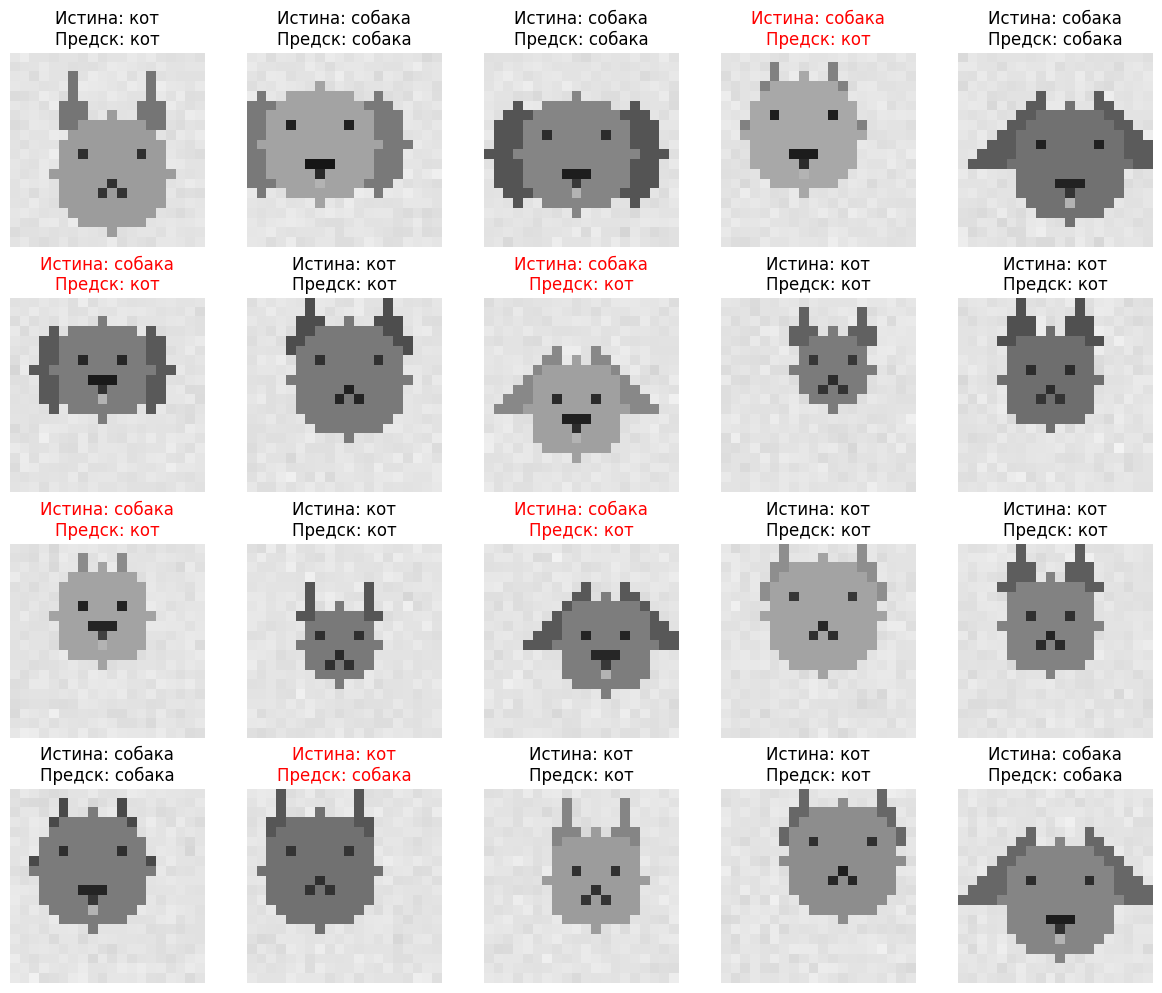

In [366]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(n_estimators=100)

clf.fit(X, y)
print("Оценка на начальных данных:", clf.score(X, y))

from sklearn.metrics import classification_report

y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["кот (0)", "собака (1)"]))

fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for i in range(20):
    axis = axes[i // 5, i % 5]
    axis.axis("off")

    true_label = "кот" if y_test[i] == 0 else "собака"
    pred_label = "кот" if y_pred[i] == 0 else "собака"

    #если ошибка, то красим заголовок в красный
    color = "black" if true_label == pred_label else "red"
    axis.set_title(f"Истина: {true_label}\nПредск: {pred_label}", color=color)

    axis.imshow(X_test[i].reshape(20, 20), cmap="gray", vmin=0, vmax=255)

plt.tight_layout()
plt.show()


Получаем 1 на начальных. И получаем ~0.72 на тестовых. Неплохой результат, в отличие от просто решающего дерева. Но его можно попытаться улучшить, если использовать другие ансамблевые методы.

#### Stacking

Этот метод построен на том, что мы обучаем некоторое количество моделей, а потом для решения используем не голосование большинства или среднее, а еще одно дерево решений.

Оценка на начальных данных: 1.0
              precision    recall  f1-score   support

     кот (0)       0.74      0.52      0.61      1977
  собака (1)       0.64      0.82      0.72      2023

    accuracy                           0.67      4000
   macro avg       0.69      0.67      0.66      4000
weighted avg       0.69      0.67      0.66      4000



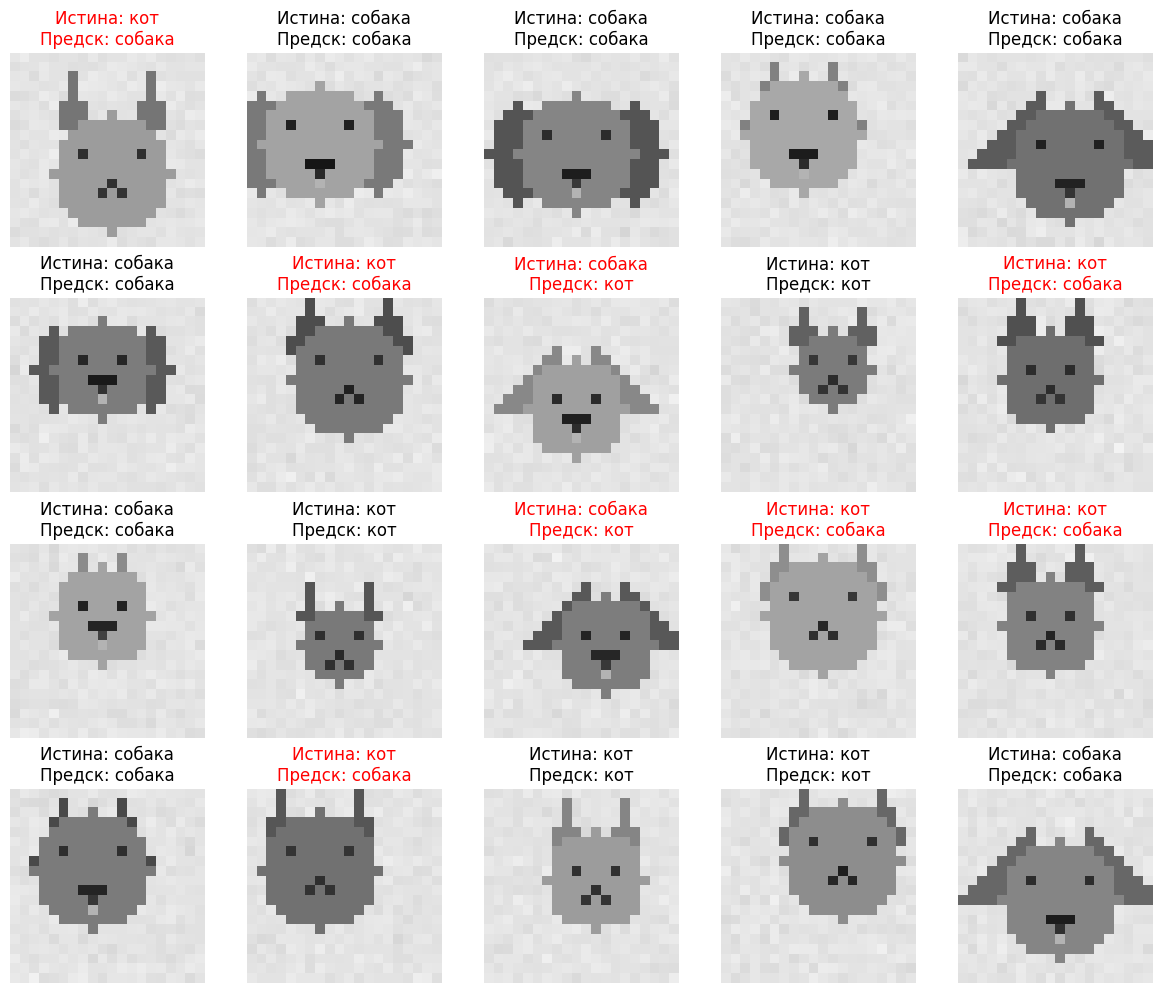

In [373]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier

base_estimators = [("rf", RandomForestClassifier(n_estimators=100))]
clf = StackingClassifier(
    estimators=base_estimators,
    final_estimator=DecisionTreeClassifier(max_depth=1)
)

clf.fit(X, y)
print("Оценка на начальных данных:", clf.score(X, y))

from sklearn.metrics import classification_report

y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["кот (0)", "собака (1)"]))

fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for i in range(20):
    axis = axes[i // 5, i % 5]
    axis.axis("off")

    true_label = "кот" if y_test[i] == 0 else "собака"
    pred_label = "кот" if y_pred[i] == 0 else "собака"

    #если ошибка, то красим заголовок в красный
    color = "black" if true_label == pred_label else "red"
    axis.set_title(f"Истина: {true_label}\nПредск: {pred_label}", color=color)

    axis.imshow(X_test[i].reshape(20, 20), cmap="gray", vmin=0, vmax=255)

plt.tight_layout()
plt.show()


Результат стал хуже, чем у просто bagging без решающего дерева. Вероятно, мы переобучили модель. В данном случае решающее дерево в конце нам мешает (даже если max_depth)

#### Boosting

Теперь мы используем метод, который повзоляет нам обучать каждую следующую модель не только на выходе прошлой, но и на начальных данных. Таким образом каждая последующая модель как бы пытается исправить ошибки прошлой.

Оценка на начальных данных: 1.0
              precision    recall  f1-score   support

     кот (0)       0.57      0.74      0.64      1977
  собака (1)       0.64      0.45      0.53      2023

    accuracy                           0.59      4000
   macro avg       0.60      0.59      0.58      4000
weighted avg       0.60      0.59      0.58      4000



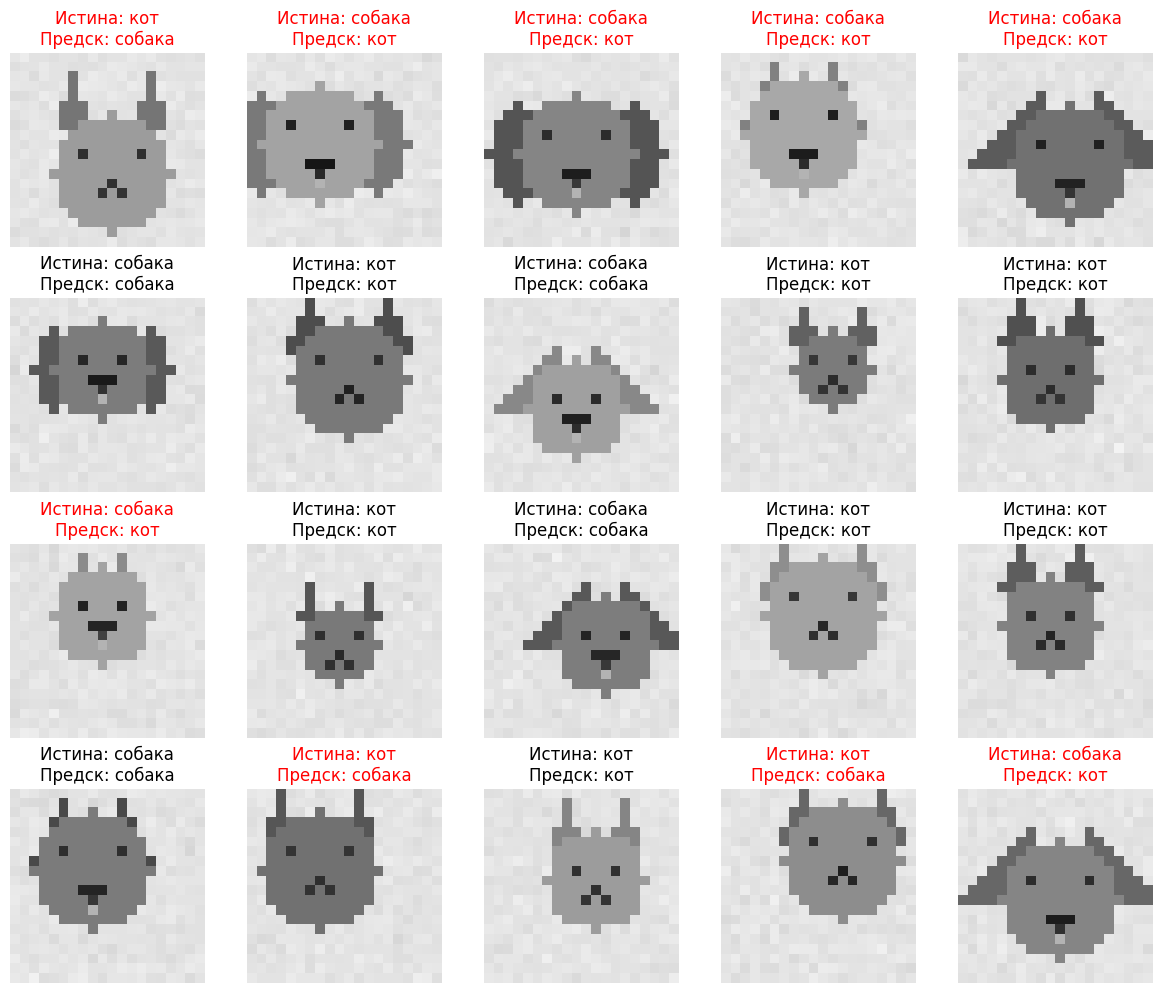

In [377]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report

clf = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1)

clf.fit(X, y)
print("Оценка на начальных данных:", clf.score(X, y))


y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["кот (0)", "собака (1)"]))

fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for i in range(20):
    axis = axes[i // 5, i % 5]
    axis.axis("off")

    true_label = "кот" if y_test[i] == 0 else "собака"
    pred_label = "кот" if y_pred[i] == 0 else "собака"

    #если ошибка, то красим заголовок в красный
    color = "black" if true_label == pred_label else "red"
    axis.set_title(f"Истина: {true_label}\nПредск: {pred_label}", color=color)

    axis.imshow(X_test[i].reshape(20, 20), cmap="gray", vmin=0, vmax=255)

plt.tight_layout()
plt.show()


И здесь мы получаем результат, как у начального решающего дерева. Он стал еще хуже. Видимо мы имеем слишком небольшой датасет для того, чтобы пытаться использовать ансамблевые методы только для деревьев решений.

## Хак одним пикселем

Для хака одним пикселем, я выбираю обычное решающее дерево, потому что его можно наглядно рассмотреть. Оно как будто создано для этого.

Оценка на начальных данных: 1.0


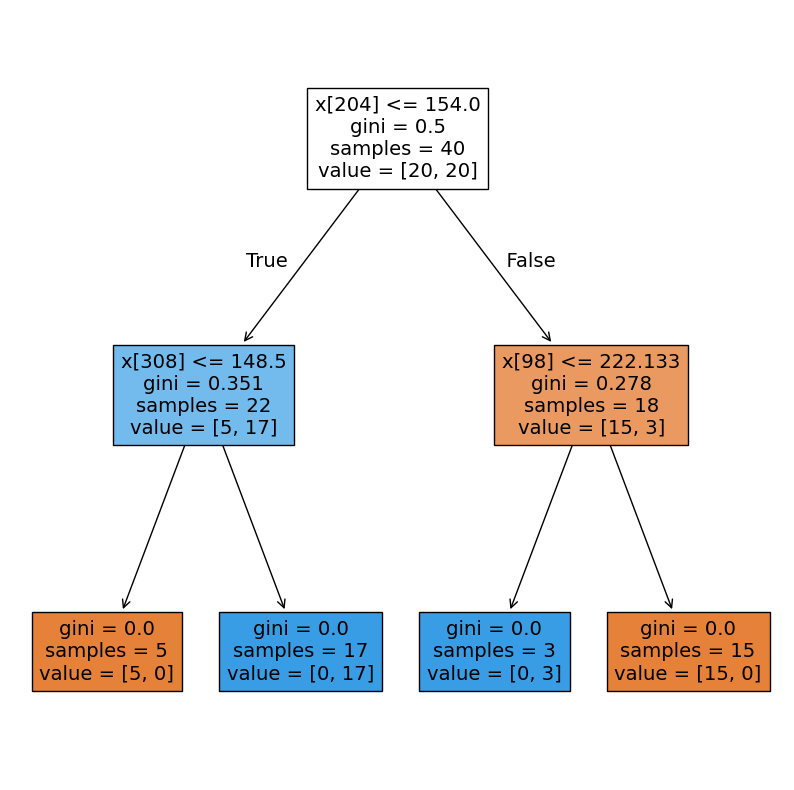

In [379]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

clf = DecisionTreeClassifier()
clf.fit(X, y)
print("Оценка на начальных данных:", clf.score(X, y))

plt.figure(figsize=(10, 10))
plot_tree(clf, filled=True)
plt.show()


Смотрим на построенное дерево: оно вышло совсем небольшим. Выберем одно изображение из обучающего датасета и изменим один пиксель так, чтобы одна из вторых (окончательно решающих) нод дала неверный ответ.

Предсказанное:  собака


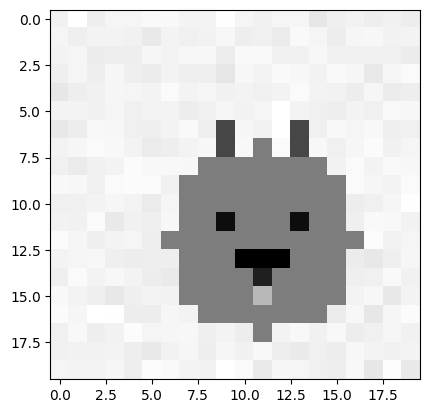

In [398]:
plt.imshow(X[0].reshape(20, 20), cmap="gray")

def decide_who(X, y_pred):
  decision = clf.predict(X[:1])[0]
  if decision == 0:
    return "кот"
  else:
    return "собака"

print("Предсказанное: ", decide_who(X, y))

Теперь смотрим на наше решающее дерево и делаем первую проверку, чтобы понять, какой из пикселей нам изменять.

In [388]:
print("Первый пиксель, по которому происходит решение равен: ", X[0][204])
print("Первая проверка: ", X[0][204] <= 154.0)

Первый пиксель, по которому происходит решение равен:  227.46666666666667
Первая проверка:  False


Это изображение идет направо. Теперь смотрим на следующую проверку.

In [389]:
print("Второй пиксель, по которому происходит решение равен: ", X[0][98])
print("Вторая проверка: ", X[0][98] <= 222.133)

Второй пиксель, по которому происходит решение равен:  221.0
Вторая проверка:  True


Это изорбражение отходит налево. Теперь мы можем изменить 1 пиксель так, что предсказанное изменится.

Предсказанное:  кот


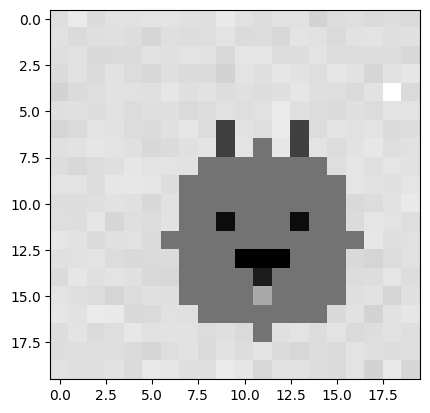

In [400]:
X_1pix = X[:1].copy()
X_1pix[0][98] = 255

plt.imshow(X_1pix[0].reshape(20, 20), cmap="gray")
plt.

print("Предсказанное: ", decide_who(X_1pix, y))

Мы изменили один пиксель и теперь наша модель ошиблась